#### Import all the Required Libraries

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

#### Load the dataset

In [85]:
df = pd.read_csv("retail_sales_2023.csv")
df.head()

,Date,Sales
0,2023-01-01,100.000000
1,2023-01-02,99.859932
2,2023-01-03,102.243640
3,2023-01-04,106.409779
4,2023-01-05,103.747803


In [86]:
df.dtypes  # The Date is in object format we need to convert it to back to Date Format. 

Date      object
Sales    float64
dtype: object

In [87]:
df["Date"] = pd.to_datetime(df["Date"])
df.dtypes  # we can see the dtype of date has been chnaged to datetime.

Date     datetime64[ns]
Sales           float64
dtype: object

In [88]:
df.set_index("Date", inplace=True) # Now let's set Date as the index of the dataset
df = df.sort_index() #sort the index to make sure the data is in the current order

In [89]:
df.head()

,Sales
Date,
2023-01-01,100.000000
2023-01-02,99.859932
2023-01-03,102.243640
2023-01-04,106.409779
2023-01-05,103.747803


In [90]:
df.tail()

,Sales
Date,
2023-12-27,228.951635
2023-12-28,233.804362
2023-12-29,231.901392
2023-12-30,232.400915
2023-12-31,233.675816


In [91]:
ts = df["Sales"]

In [92]:
ts.head()

Date
2023-01-01    100.000000
2023-01-02     99.859932
2023-01-03    102.243640
2023-01-04    106.409779
2023-01-05    103.747803
Name: Sales, dtype: float64

In [93]:
ts.tail()

Date
2023-12-27    228.951635
2023-12-28    233.804362
2023-12-29    231.901392
2023-12-30    232.400915
2023-12-31    233.675816
Name: Sales, dtype: float64

#### Lets Plot the Sales data across last 1 year

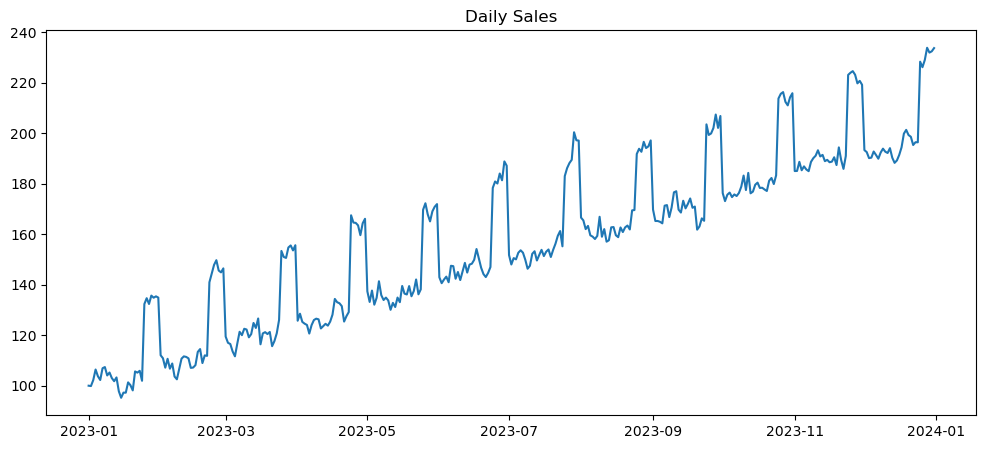

In [94]:
plt.figure(figsize=(12,5))
plt.plot(ts)
plt.title("Daily Sales")
plt.show()

#### Time Series Decomposition (Trend, Seasonality, Residual)

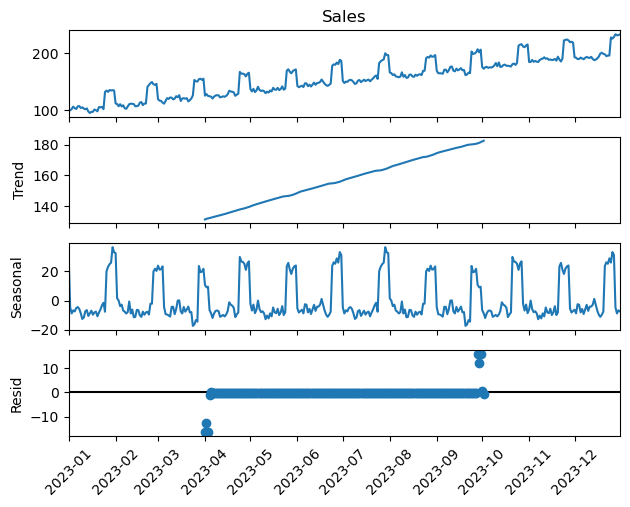

In [96]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomp = seasonal_decompose(ts,model="additive",period=180)
decomp.plot()
plt.xticks(rotation=45)
plt.show()

In [97]:
# we can clearly see the trend is Increasing. 
# The seasonality alos exists, at the end of every year the sales always jump high.

#### Checkign for Stationarity - Visually

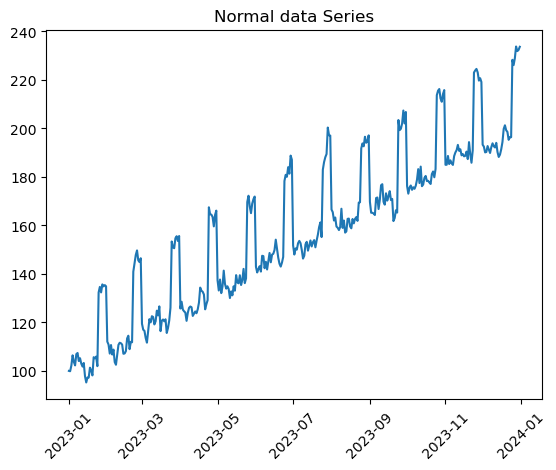

In [98]:
plt.plot(ts)
plt.title("Normal data Series")
plt.xticks(rotation=45)
plt.show()

In [99]:
# From the plot we can clearly see that the data is non stationary. 

#### Checking for Stationarity using ADF Test

In [100]:
from statsmodels.tsa.stattools import adfuller


adf_test_stat,p_value = adfuller(ts)[0:2]
print("ADF Statistic:",adf_test_stat)
print("p-value:", p_value)
if p_value <= 0.05:
    print("Since p_value is not less than the significance level We can conclude the time series is Stationary")
else:
    print("Since p_value is less than the significance level We can conclude the time series is Non-Stationary")

ADF Statistic: -1.1306216283770174
p-value: 0.7027071873305626
Since p_value is less than the significance level We can conclude the time series is Non-Stationary


### Let's Make the time series data Stationary by using 
#### Differencing technique

In [101]:
ts_diff = ts.diff().dropna()

#### Checkign for Stationarity on differenced data - Visually

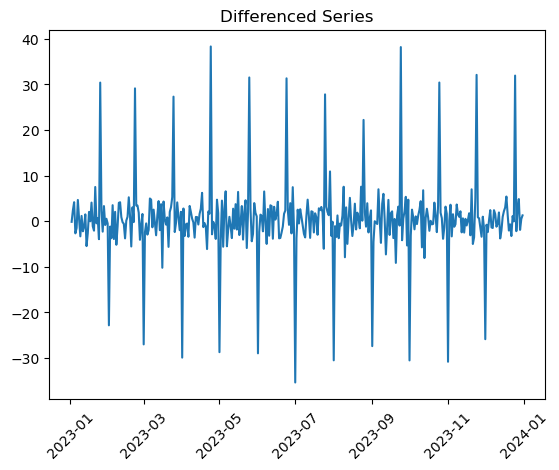

In [102]:
plt.plot(ts_diff)
plt.title("Differenced Series")
plt.xticks(rotation=45)
plt.show()

In [103]:
# From the plot we can clearly see that the differenced data is non stationary.

#### Checking for Stationarity on differenced data using ADF Test

In [104]:
adf_test_stat,p_value = adfuller(ts_diff)[0:2]
print("ADF Statistic:",adf_test_stat)
print("p-value:", p_value)
if p_value <= 0.05:
    print("Since p_value is not less than the significance level We can conclude the time series is Stationary")
else:
    print("Since p_value is less than the significance level We can conclude the time series is Non-Stationary")

ADF Statistic: -7.608297877473784
p-value: 2.2908330021053304e-11
Since p_value is not less than the significance level We can conclude the time series is Stationary


In [105]:
##### After applying first order differencing we can clearly see the time series data is more stationary.

### Now lets split the data in to train and test sets

In [106]:
ts.index = pd.to_datetime(ts.index)
ts_diff.index = pd.to_datetime(ts_diff.index)

In [107]:
#since we are using a time series data of 3 years the order of the data is very important. we cannot randomly split the data in to 70:30 or 80:20 splits.
#We have to split the data in sequency like first 80% as train and than last 20% as test we neeed to turn off Shuffle parameter to do this. 


from sklearn.model_selection import train_test_split

In [108]:
len(ts)

365

In [109]:
len(ts_diff) # when we are differencing the first value will not have any data point

364

In [111]:
original_train,original_test  = train_test_split(ts,train_size=len(ts)-60,test_size=60,shuffle=False)   
stationary_train,stationary_test  = train_test_split(ts_diff,train_size=len(ts)-60,test_size=59,shuffle=False)   


#shuffle = True  # splits the data randomly
#shuffle = False # splits the data in the sequence order

In [112]:
original_train.head()

Date
2023-01-01    100.000000
2023-01-02     99.859932
2023-01-03    102.243640
2023-01-04    106.409779
2023-01-05    103.747803
Name: Sales, dtype: float64

In [113]:
original_test.tail()

Date
2023-12-27    228.951635
2023-12-28    233.804362
2023-12-29    231.901392
2023-12-30    232.400915
2023-12-31    233.675816
Name: Sales, dtype: float64

In [114]:
stationary_train.head()

Date
2023-01-02   -0.140068
2023-01-03    2.383708
2023-01-04    4.166139
2023-01-05   -2.661976
2023-01-06   -1.487246
Name: Sales, dtype: float64

In [115]:
stationary_test.tail()

Date
2023-12-27    2.837767
2023-12-28    4.852728
2023-12-29   -1.902970
2023-12-30    0.499523
2023-12-31    1.274901
Name: Sales, dtype: float64

lets proceed to build timeseries Models. 

AR --> MA --> ARMA --> ARIMA --> SARIMA

| Model  | Data Used  |  Reason |          
| ------ | ---------- |  -------- |
| AR     | Stationary | - AR Model Requires data to be Statioanry |
| MA     | Stationary | - MA Model Requires data to be Statioanry |
| ARMA   | Stationary | - ARMA Model Requires data to be Statioanry |
| ARIMA  | Original   | - ARIMA Model can handle non-stationary data |
| SARIMA | Original   | - SARIMA Model can handle non-stationary data |

#### AutoRegressive Model (AR)

In [116]:
from statsmodels.tsa.ar_model import AutoReg
import warnings
warnings.filterwarnings('ignore')

In [117]:
ar_model = AutoReg(stationary_train, lags=1).fit() 
# lag means how many previous values we need to use to predict the observations.
ar_forecast = ar_model.forecast(steps=len(stationary_test))


In [148]:
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

In [119]:
mse = mean_squared_error(stationary_test, ar_forecast)
mape = mean_absolute_percentage_error(stationary_test, ar_forecast)
print('Mean Squared Error:',mse)
print('Mean Absolute Percentage Error:',mape)

Mean Squared Error: 51.767352140516266
Mean Absolute Percentage Error: 1.0937274930966263


### Moving Average Model (MA)

ARIMA(data, order=(p, d, q)

order (p,d,q)  means:


| Parameter | Meaning                |
| --------- | ---------------------- |
| p         | Number of AR lags  (How many previous values to use for prediction |
| d         | Number of differencing (How many times we subtract previous value) |
| q         | Number of MA lags   (How many prevoius errors to use for prediction|


In [121]:
from statsmodels.tsa.arima.model import ARIMA

ma_model = ARIMA(stationary_train, order=(0,0,1)).fit()
ma_forecast = ma_model.forecast(steps=len(stationary_test))

In [149]:
mse = mean_squared_error(stationary_test, ma_forecast)
mape = mean_absolute_percentage_error(stationary_test, ma_forecast)
print('Mean Squared Error:',mse)
print('Mean Absolute Percentage Error:',mape)

Mean Squared Error: 51.76820526301508
Mean Absolute Percentage Error: 1.0929240516057068


#### AutoRegressiveMovingAverage Model (ARMA) 

ARIMA(data, order=(p, d, q)

order (p,d,q)  means:


| Parameter | Meaning                |
| --------- | ---------------------- |
| p         | Number of AR lags      |
| d         | Number of differencing |
| q         | Number of MA lags      |


In [129]:
arma_model = ARIMA(stationary_train, order=(1,0,1)).fit()
arma_forecast = arma_fit.forecast(steps=len(stationary_test))

In [132]:
mse = mean_squared_error(stationary_test, arma_forecast)
mape = mean_absolute_percentage_error(stationary_test, arma_forecast)
print('Mean Squared Error:',mse)
print('Mean Absolute Percentage Error:',mape)

Mean Squared Error: 50.17459306459441
Mean Absolute Percentage Error: 1.9364597839537208


#### AutoRegressiveIntegratedMovingAverage Model (ARIMA) 

In [136]:
arima_model = ARIMA(original_train, order=(1,1,1)).fit()
arima_forecast = arima_fit.forecast(len(original_test))

In [137]:
mse = mean_squared_error(original_test, arima_forecast)
mape = mean_absolute_percentage_error(original_test, arima_forecast)
print('Mean Squared Error:',mse)
print('Mean Absolute Percentage Error:',mape)

Mean Squared Error: 30546.453013631006
Mean Absolute Percentage Error: 0.8719606953923896


#### SeasonalAutoRegressiveIntegratedMovingAverage Model (SARIMA) 

In [138]:
from statsmodels.tsa.statespace.sarimax import SARIMAX


sarima_model = SARIMAX(original_train,
                       order=(1,1,1),
                       seasonal_order=(1,1,1,30)).fit(maxiter=50)

sarima_pred = sarima_model.forecast(steps=len(original_test))

In [139]:
mse = mean_squared_error(original_test, sarima_pred)
mape = mean_absolute_percentage_error(original_test, sarima_pred)
print('Mean Squared Error:',mse)
print('Mean Absolute Percentage Error:',mape)

Mean Squared Error: 69.25232600377764
Mean Absolute Percentage Error: 0.025546496977021604


In [142]:
original_pred_data = pd.concat([original_test,sarima_pred],axis=1)

#### Future Forecast (Best Model: SARIMA)

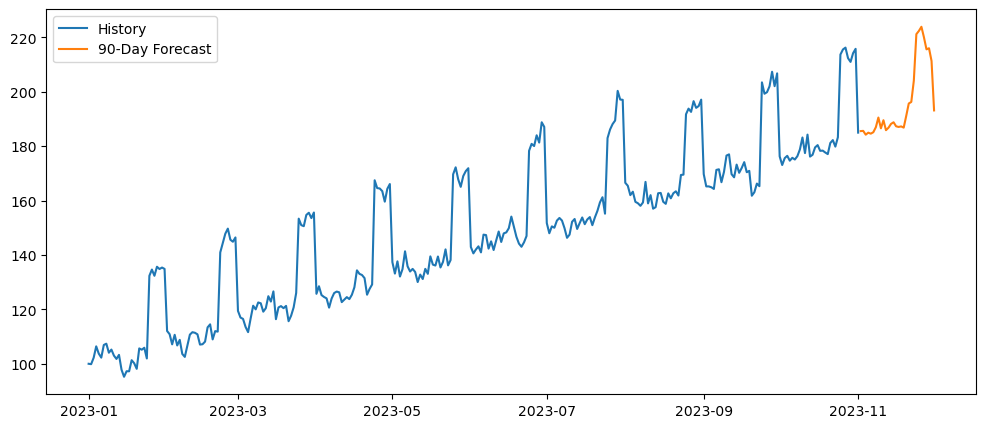

In [147]:
future = sarima_model.forecast(30)

plt.figure(figsize=(12,5))
plt.plot(original_train, label="History")
plt.plot(future, label="90-Day Forecast")

plt.legend()
plt.show()
